# DeepAR forecast demo

Train a probabilistic DeepAR model on synthetic autoregressive data using the current task API.
The task minimizes Gaussian negative log likelihood and gradually reduces teacher forcing.
At inference, `generate()` samples complete trajectories and returns their mean and sample paths.
Training duration and random seeds affect the resulting metrics; this notebook is a workflow example.


## Setup

Install TFTS and the notebook dependencies into the kernel environment before running all cells:

```python
%pip install tfts matplotlib
```

Use a TFTS release matching these docs. To test the current checkout, install it with `pip install -e .` first. This notebook imports the installed package and does not require repository-only helpers.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

from tfts import AutoConfig, AutoModel, AutoModelForForecasting, ForecastTaskConfig, GenerationConfig

tf.keras.utils.set_random_seed(42)
ENCODER_LENGTH = 60
PREDICTION_LENGTH = 20
N_SAMPLES = 100
EPOCHS = 12
BATCH_SIZE = 128

## 1. Data

Generate synthetic series with trend, seasonality, and noise using the installed `tfts.datasets.load_ar` loader. This replaces the historical repository-only generator; the random series and resulting metrics differ from the old notebook.

In [2]:
from tfts.datasets import load_ar

data = load_ar(seasonality=10.0, timesteps=400, n_series=100, seed=42)
print(data.head())
print(
    "rows:",
    len(data),
    "| series:",
    data.series.nunique(),
    "| time range:",
    data.time_idx.min(),
    "-",
    data.time_idx.max(),
)

   series  time_idx     value
0       0         0  1.696325
1       0         1  1.817511
2       0         2  1.986875
3       0         3  1.813084
4       0         4  2.035635
rows: 40000 | series: 100 | time range: 0 - 399


## 2. Windowing and normalization

Hold out the final forecast horizon of each series. Fit normalization on training rows only.
The model receives `past_values` and static series IDs; the task handles teacher feedback from labels.


In [3]:
from tfts.data import FramePipeline, Schema
from tfts.data.schema import FeatureSpec
from tfts.data.tf_dataset import SequenceMaterializer

schema = Schema(
    "time_idx", ("value",), group_cols=("series",), features=(FeatureSpec("series", "static", "categorical"),)
)
pipeline = FramePipeline(schema, context=ENCODER_LENGTH, horizon=PREDICTION_LENGTH)
prepared, train_windows, valid_windows = pipeline.fit(data, validation=PREDICTION_LENGTH / 400)
train_ds = pipeline.dataset(prepared, train_windows, batch_size=BATCH_SIZE, shuffle=True, seed=42)
val_ds = pipeline.dataset(prepared, valid_windows, batch_size=BATCH_SIZE)
val_batch = SequenceMaterializer().materialize(prepared, valid_windows)
val_inputs = {
    "past_values": val_batch.past_values,
    "static_categorical_features": val_batch.static_categorical_features,
}
print("training windows:", len(train_windows))
print("validation x/y:", val_batch.past_values.shape, val_batch.future_values.shape)
print("training-only target scaler:", pipeline.target_scaler.to_dict())

training windows: 30100
validation x/y: (100, 60, 1) (100, 20, 1)
training-only target scaler: {'method': 'standard', 'offset': [0.018615052103996277], 'scale': [2.1971206665039062]}


## 3. Build the model
Use canonical target histories and static series IDs. The task owns Gaussian NLL and scheduled sampling.

In [4]:
cfg = AutoConfig.for_model("deep_ar")
cfg.n_series = len(pipeline.vocabularies["series"]) + 1
steps_per_epoch = int(np.ceil(len(train_windows) / BATCH_SIZE))
forecast_model = AutoModelForForecasting.from_config(
    cfg,
    task_config=ForecastTaskConfig(
        output_chunk_length=PREDICTION_LENGTH,
        head="native",
        feedback_sampler="sample",
        teacher_probability=1.0,
        teacher_final_probability=0.2,
        teacher_decay_steps=EPOCHS * steps_per_epoch,
    ),
)

## 4. Train with scheduled sampling
The task's default objective is Gaussian negative log likelihood. Teacher probability decays from 1.0 to 0.2 over training.

In [5]:
forecast_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=0.1))
history = forecast_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=2)

Epoch 1/12


/Users/longxingtan/Repository/Time-series-prediction/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


/Users/longxingtan/Repository/Time-series-prediction/.venv/lib/python3.12/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'forecasting_model', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


236/236 - 22s - 94ms/step - loss: 0.2025 - val_loss: 0.1699


Epoch 2/12


...

236/236 - 10s - 42ms/step - loss: -8.4261e-01 - val_loss: -3.5319e-01


Epoch 11/12


236/236 - 10s - 43ms/step - loss: -8.6595e-01 - val_loss: -3.2805e-01


Epoch 12/12


236/236 - 11s - 46ms/step - loss: -8.9283e-01 - val_loss: 0.1480


## 5. Evaluate ancestral samples

`generate()` draws complete trajectories, feeding each sampled value into the next step.
Inverse-transform the mean predictions and samples to report and plot original units.


In [6]:
gen = forecast_model.generate(val_inputs, config=GenerationConfig(mode="native", num_samples=N_SAMPLES, seed=0))
preds = pipeline.target_scaler.inverse_transform(gen.predictions.numpy())[..., 0]
actual = pipeline.target_scaler.inverse_transform(val_batch.future_values.numpy())[..., 0]
assert preds.shape == actual.shape
assert np.isfinite(preds).all()
err = actual - preds
print("MAE:", float(np.abs(err).mean()))
print("MSE:", float(np.mean(err**2)))

MAE: 0.6966856718063354
MSE: 1.1594818830490112


## 6. Plot a forecast


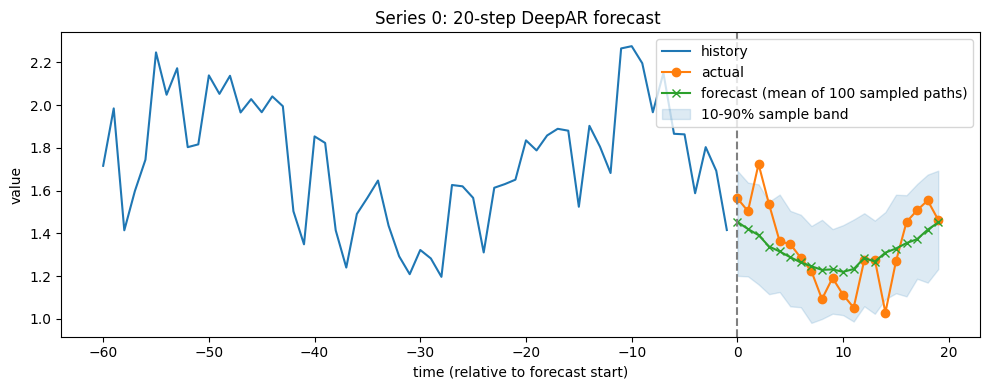

In [7]:
s = 0  # pick a series
window = pipeline.target_scaler.inverse_transform(val_batch.past_values.numpy())[
    s, :, 0
]  # normalized history (encoder window)
fut = np.arange(PREDICTION_LENGTH)

plt.figure(figsize=(10, 4))
plt.plot(np.arange(-ENCODER_LENGTH, 0), window, label="history")
plt.plot(fut, actual[s], label="actual", marker="o")
plt.plot(fut, preds[s], label="forecast (mean of 100 sampled paths)", marker="x")
samples = pipeline.target_scaler.inverse_transform(gen.samples.numpy())[s, :, :, 0]  # (num_samples, pred_len)
lo, hi = np.percentile(samples, 10, axis=0), np.percentile(samples, 90, axis=0)
plt.fill_between(fut, lo, hi, alpha=0.15, color="tab:blue", label="10-90% sample band")
plt.axvline(0, color="gray", ls="--")
plt.xlabel("time (relative to forecast start)")
plt.ylabel("value")
plt.legend()
plt.title(f"Series {s}: {PREDICTION_LENGTH}-step DeepAR forecast ")
plt.tight_layout()
plt.show()

## 7. Save, reload, and run inference
Use `generate()` for ancestral-sampling inference on the restored model.


In [8]:
# Save the task and fitted preprocessing together.
model_dir = Path("deepar_model")
sample = {name: values[:1] for name, values in val_inputs.items()}
_ = forecast_model(sample)
forecast_model.save_pretrained(model_dir)
(model_dir / "pipeline.json").write_text(json.dumps(pipeline.to_dict()))
restored_model = AutoModel.from_pretrained(model_dir, sample_batch=sample)
restored_pipeline = FramePipeline.from_dict(json.loads((model_dir / "pipeline.json").read_text()))
restored_gen = restored_model.generate(
    val_inputs, config=GenerationConfig(mode="native", num_samples=N_SAMPLES, seed=0)
)
restored_preds = restored_pipeline.target_scaler.inverse_transform(restored_gen.predictions.numpy())[..., 0]
np.testing.assert_allclose(restored_preds, preds, rtol=1e-5, atol=1e-5)
print("Restored prediction shape:", restored_preds.shape)
print("Restored MAE:", float(np.abs(actual - restored_preds).mean()))

/Users/longxingtan/Repository/Time-series-prediction/.venv/lib/python3.12/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'forecasting_model_1', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Restored prediction shape: (100, 20)
Restored MAE: 0.6966856718063354
